# 00.06 — One full episode line by line

<div><span style="display:inline-block;background:#8B5CF6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPISODE</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #8B5CF6;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#8B5CF6">EPISODE</div><div style="font-size:21px;font-weight:800;margin-top:4px">Episode</div><div style="font-size:15px;line-height:1.55;margin-top:8px">One full run from `reset()` until termination/truncation. `range(300)` means do 300 runs; the loop variable is 0…299.</div></div>

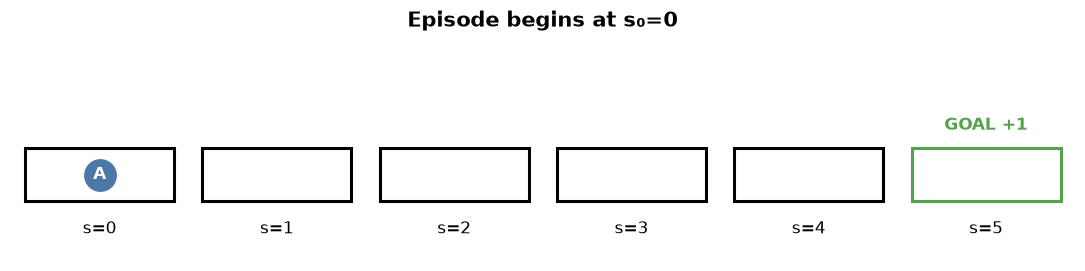

In [2]:
env=LineWorld(); obs,_=env.reset(); fig=lineworld(obs,title="Episode begins at s₀=0"); plt.show()

To isolate the concept, force RIGHT every time for one episode.

,t,s,a,s_prime,r,terminated,truncated
0,0,0,1,1,-0.02,False,False
1,1,1,1,2,-0.02,False,False
2,2,2,1,3,-0.02,False,False
3,3,3,1,4,-0.02,False,False
4,4,4,1,5,1.00,True,False


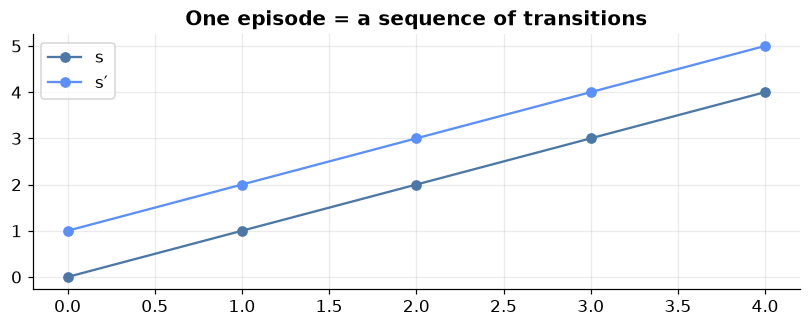

In [3]:
env=LineWorld(); obs,_=env.reset(); rows=[]
for t in range(5):
    s=obs; a=1; n,r,term,trunc,info=env.step(a); rows.append([t,s,a,n,r,term,trunc]); obs=n
    if term or trunc: break
df=pd.DataFrame(rows,columns=["t","s","a","s_prime","r","terminated","truncated"]); display(df)
plt.figure(figsize=(9,3)); plt.plot(df.t,df.s,marker="o",label="s",color=COLORS["STATE"]); plt.plot(df.t,df.s_prime,marker="o",label="s′",color=COLORS["S PRIME"]); plt.yticks(range(6)); plt.title("One episode = a sequence of transitions"); plt.legend(); plt.show()

Each row is an experience tuple `(s, a, r, s′)`. A trajectory is a sequence of those tuples.

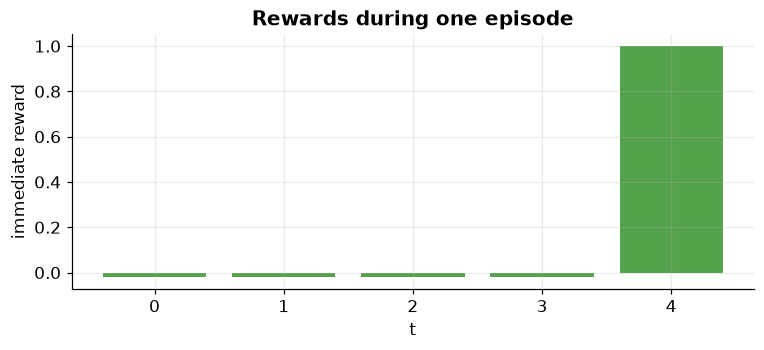

undiscounted return = 0.92


In [4]:
plt.figure(figsize=(8,3)); plt.bar(df.t,df.r,color=COLORS["REWARD"]); plt.xlabel("t"); plt.ylabel("immediate reward"); plt.title("Rewards during one episode"); plt.show()
print("undiscounted return =",df.r.sum())

`if term or trunc: break` means stop this episode if either the task naturally ended or an outside time limit cut it off.

In LineWorld, `obs == state`, so `Q[obs,action]` really is `Q[s,a]`. In a POMDP/LifeOS setting, raw observation is not necessarily a sufficient Markov state; a representation may need history.